# Ⅰ第4回 演習3 保存したモデルを別のファイルで使う

**問い**：演習1 で保存した CNN は，学習に使っていない **新しい写真** を見分けられるか．既存の LLM ならどうか．

第2回の「学習済みの重みを読む」と同じ 5 つの手順（読む → 組み立てる → 重みを入れる → 評価モード → 推論）を，自分のモデルで行う．
このノートブックでは学習しない（optimizer・`loss.backward()` は使わない）．

## (0) 番号の設定

In [1]:
# ===== (0) 番号の設定 =====
MEMBER_NO = 2                 # ← グループ内の自分の番号 (1〜5)．presenter はこの番号の順に演習ごとに交代する

# 授業用フォルダ（AI_TD）のルートを import パスに追加する（ノートブックをどこから開いても動く）
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".dlcourse_root").exists())
sys.path.insert(0, str(ROOT))
print("作業フォルダ:", ROOT)

作業フォルダ: /Users/niirowakana/AI_TD


## (1) 新しい写真を用意する（10 分）

1. 演習1 と同じ 2 つのクラスを，**各 5 枚** 新しく撮る（学習に使った写真は使わない．撮る場所や背景を変えてもよい）
2. `assets/mynew_photos/<クラス名>/` に入れる（フォルダ名は `assets/myphotos/` と同じにする）
3. ターミナルで `python setup/prepare_mydata.py --new` を実行する（`assets/mynew/` にそろう）

ケーブル画像で進めた人は，そのまま次へ（ケーブル画像から 10 枚を使う．学習に使った写真が混ざる）．

## (2) 手順 1：重みのファイルを読む

In [3]:
import torch
import torch.nn as nn
from torchvision import transforms
from torchvision.datasets import ImageFolder
import pandas as pd
import matplotlib.pyplot as plt
from common.device import get_device
from common.todo import checkpoint
plt.rcParams["font.family"] = ["Hiragino Sans", "sans-serif"]   # Mac の日本語フォント（文字化け防止）

device = get_device()
ckpt = torch.load(ROOT / "results" / "my_cnn.pt", map_location=device)   # 演習1 の最後で保存したファイル
class_names = ckpt["classes"]
size = ckpt["image_size"]
print("入っているもの:", list(ckpt))
print("クラス:", class_names, "| 画像の大きさ:", size, "| 演習1 のテスト正解率:", f"{ckpt['test_accuracy'] * 100:.1f}%")
c, h, w = 3, size, size    # ⑦で使う名前を，保存した値から作る

入っているもの: ['state_dict', 'classes', 'image_size', 'test_accuracy']
クラス: ['dislike', 'like'] | 画像の大きさ: 64 | 演習1 のテスト正解率: 80.0%


## (3) 手順 2：同じ構造を組み立てる

演習1 の **⑦（CNN）のセルをコピーして** 下に貼る．`len(full_dataset.classes)` は `len(class_names)` に直す（このファイルには `full_dataset` が無い）．

In [4]:
# 入力画像のチャネル数・高さ・幅
INPUT_CHANNELS = c
IMAGE_HEIGHT = h
IMAGE_WIDTH = w

# 畳み込み層が出す特徴マップの枚数
CONV1_OUT_CHANNELS = 16

# 3×3 のフィルタで画像をなぞる．PADDING で縁を補い，POOL_SIZE で縦横を半分にする
KERNEL_SIZE = 3
PADDING = 1
POOL_SIZE = 2

POOL_NUM = 1

FC1_OUT_CHANNELS = 128

# 出力の数 = 分類するクラスの数
OUTPUT_SIZE = len(class_names)

# プーリング後の高さと幅（64 → 32）
OUT_HEIGHT = IMAGE_HEIGHT // (POOL_SIZE ** POOL_NUM)
OUT_WIDTH = IMAGE_WIDTH // (POOL_SIZE ** POOL_NUM)

# 全結合層に渡す長さ = 特徴マップの枚数 × 高さ × 幅
FLATTEN_SIZE = CONV1_OUT_CHANNELS * OUT_HEIGHT * OUT_WIDTH 

# 層を上から順に積み重ねてモデルを作る
model = nn.Sequential(
    # 畳み込み層：小さなフィルタで模様（特徴）を取り出す
    nn.Conv2d(INPUT_CHANNELS, CONV1_OUT_CHANNELS, kernel_size=KERNEL_SIZE, padding=PADDING),
    # 活性化関数：負の値を 0 にする
    nn.ReLU(),
    # プーリング：2×2 の中の最大値だけを残して縮小する
    nn.MaxPool2d(kernel_size=POOL_SIZE),
    # 画像（または特徴マップ）を 1 列のベクトルに伸ばす
    nn.Flatten(),
    # 全結合層：すべての入力とつながる
    nn.Linear(FLATTEN_SIZE, FC1_OUT_CHANNELS),
    nn.ReLU(),
    nn.Linear(FC1_OUT_CHANNELS, OUTPUT_SIZE)
)

# モデルを計算装置に載せる
model = model.to(device)

# 試しに 1 枚分のデータを通し，出力の形が (1, 2) になるかを確かめる
dummy_input = torch.randn(1, INPUT_CHANNELS, IMAGE_HEIGHT, IMAGE_WIDTH).to(device)
output = model(dummy_input)
print("ダミー入力の出力サイズ:", output.shape)
print("　↑　")
print("torch.Size([1,2]) になることを確認してください。")

model

ダミー入力の出力サイズ: torch.Size([1, 2])
　↑　
torch.Size([1,2]) になることを確認してください。


Sequential(
  (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Flatten(start_dim=1, end_dim=-1)
  (4): Linear(in_features=16384, out_features=128, bias=True)
  (5): ReLU()
  (6): Linear(in_features=128, out_features=2, bias=True)
)

## (4) 手順 3・4：学習済みの重みを入れ，評価モードにする

In [5]:
result = model.load_state_dict(ckpt["state_dict"])    # 形が 1 つでも違うとエラーになる
print(result)                                          # <All keys matched successfully> なら成功
model.eval()                                           # 評価モード（学習のときだけの動きを止める）

<All keys matched successfully>


Sequential(
  (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Flatten(start_dim=1, end_dim=-1)
  (4): Linear(in_features=16384, out_features=128, bias=True)
  (5): ReLU()
  (6): Linear(in_features=128, out_features=2, bias=True)
)

**(確認)** 構造を変えて組み立てると，重みは入るか．下のセルは畳み込みのフィルタを 16 枚 → 8 枚にした CNN に入れてみる．

In [6]:
wrong = nn.Sequential(nn.Conv2d(3, 8, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(),
                      nn.Linear(8 * (h // 2) * (w // 2), 128), nn.ReLU(), nn.Linear(128, len(class_names)))
try:
    wrong.load_state_dict(ckpt["state_dict"])
except RuntimeError as e:
    print("エラー：", str(e).splitlines()[1][:150])
    print("→ ファイルには重みの数値しか入っていない．同じ構造を自分で組み立てないと読めない")

エラー： 	size mismatch for 0.weight: copying a param with shape torch.Size([16, 3, 3, 3]) from checkpoint, the shape in current model is torch.Size([8, 3, 3, 
→ ファイルには重みの数値しか入っていない．同じ構造を自分で組み立てないと読めない


## (5) 手順 5：新しい写真を推論する

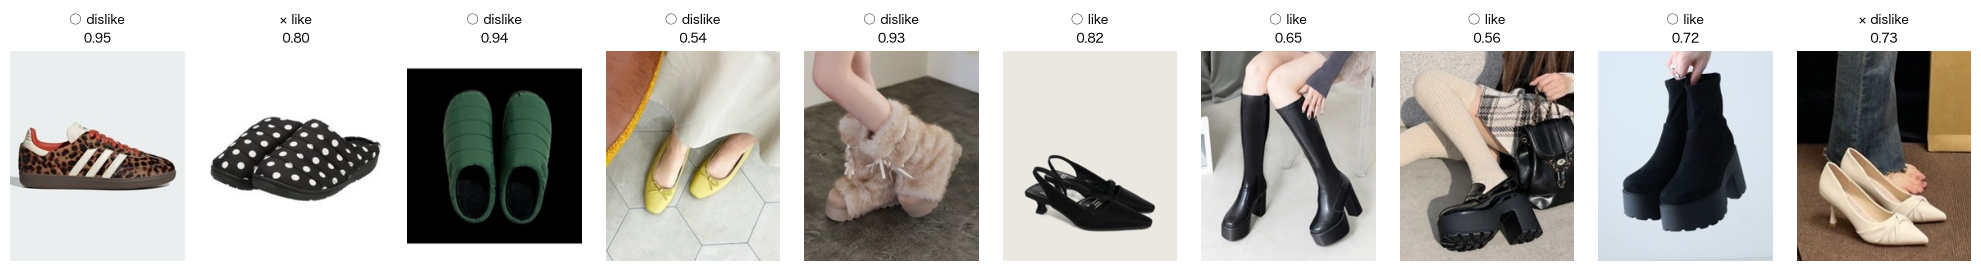

          写真       正解       予測    確率
0   い(1).jpg  dislike  dislike  0.95
1   い(2).jpg  dislike     like  0.80
2   い(3).jpg  dislike  dislike  0.94
3   い(4).jpg  dislike  dislike  0.54
4   い(5).jpg  dislike  dislike  0.93
5  い(10).jpg     like     like  0.82
6   い(6).jpg     like     like  0.65
7   い(7).jpg     like     like  0.56
8   い(8).jpg     like     like  0.72
9   い(9).jpg     like  dislike  0.73

自分のモデル：10 枚中 8 枚正解


In [7]:
from common import ASSETS
new_dir = ASSETS / "mynew"
if not new_dir.exists():
    from common.mydata import image_dir
    new_dir = image_dir()
    print("assets/mynew/ が無いので", new_dir, "から各クラス 5 枚を使う（学習に使った写真が混ざるので，正解数は高めに出る）")
photos = ImageFolder(root=str(new_dir))
if photos.classes != class_names:
    raise RuntimeError(f"新しい写真のフォルダ名 {photos.classes} が，学習したクラス {class_names} と違う")
picked = [i for k in range(len(class_names)) for i in [j for j, (_, y) in enumerate(photos.samples) if y == k][:5]]

tf = transforms.Compose([transforms.Resize((size, size)), transforms.ToTensor()])   # 演習1 の②（val）と同じ前処理
rows = []
fig, axes = plt.subplots(1, len(picked), figsize=(2 * len(picked), 2.6))
with torch.no_grad():                                   # 勾配を計算しない
    for ax, i in zip(axes, picked):
        image, label = photos[i]
        prob = torch.softmax(model(tf(image).unsqueeze(0).to(device)), dim=1)[0]   # 1 枚を (1, 3, 64, 64) にして流す
        pred = int(prob.argmax())
        rows.append({"写真": Path(photos.samples[i][0]).name, "正解": class_names[label],
                     "予測": class_names[pred], "確率": round(float(prob[pred]), 2)})
        ax.imshow(image); ax.axis("off")
        ax.set_title(f"{'○' if pred == label else '×'} {class_names[pred]}\n{float(prob[pred]):.2f}", fontsize=9)
plt.tight_layout(); plt.show()
result_df = pd.DataFrame(rows)
print(result_df.to_string())
my_correct = int((result_df["正解"] == result_df["予測"]).sum())
print(f"\n自分のモデル：{len(result_df)} 枚中 {my_correct} 枚正解")

## (6) LLM にも分類させる（討議のための実測）

ここでは LLM（ChatGPT・Gemini・Claude など）に写真を分類させる．

1. (5) と同じ写真を LLM に 1 枚ずつ渡し，次のように聞く．`A`・`B` は，クラスを **自分を知らない人に伝える言葉** で書く
   > この写真は「A」と「B」のどちらですか．A か B だけで答えてください．
2. 答えを，下のセルの `LLM_ANSWERS` に (5) の表の順にクラス名（フォルダ名）で書く

- 送るのは，顔・名前など個人が分かるものが写っていない写真だけ（送った写真は相手のサービスに残ることがある）

In [9]:
# ▼ (5) の表の順に，LLM の答えをクラス名で書く（例：["pen_mine", "pen_other", ...]）
LLM_ANSWERS = ["dislike", "dislike", "like", "dislike", "dislike", "like", "like", "dislike", "like", "like"]

if len(LLM_ANSWERS) != len(result_df):
    raise RuntimeError(f"LLM の答えが {len(LLM_ANSWERS)} 個．(5) の表と同じ {len(result_df)} 個を書く")
if set(LLM_ANSWERS) - set(class_names):
    raise RuntimeError(f"クラス名は {class_names} のどれかで書く")
result_df["LLM"] = LLM_ANSWERS
llm_correct = int((result_df["正解"] == result_df["LLM"]).sum())
print(result_df.to_string())
print(f"\n新しい写真 {len(result_df)} 枚：自分のモデル {my_correct} 枚・LLM {llm_correct} 枚 正解")

from common.logger import ResultLogger
logger = ResultLogger(None, f"member{MEMBER_NO}", course="c1", day="d4", exercise="ex3", device=device)
logger.log_many({"my_correct": my_correct, "llm_correct": llm_correct, "n_photos": len(result_df)},
                condition=f"{new_dir.name}_{'_'.join(class_names)}", seed=0)
print("記録した:", logger.path.name)

          写真       正解       予測    確率      LLM
0   い(1).jpg  dislike  dislike  0.95  dislike
1   い(2).jpg  dislike     like  0.80  dislike
2   い(3).jpg  dislike  dislike  0.94     like
3   い(4).jpg  dislike  dislike  0.54  dislike
4   い(5).jpg  dislike  dislike  0.93  dislike
5  い(10).jpg     like     like  0.82     like
6   い(6).jpg     like     like  0.65     like
7   い(7).jpg     like     like  0.56  dislike
8   い(8).jpg     like     like  0.72     like
9   い(9).jpg     like  dislike  0.73     like

新しい写真 10 枚：自分のモデル 8 枚・LLM 8 枚 正解
記録した: c1_d4_ex3.csv


## ✋ 止まる 1：ここから先へは，グループ全員がそろってから進む

**問い**：メンバーのタスクのうち，専用モデルを作る価値があったのはどれか．LLM が当てられなかったタスクには，どんな共通点があるか

1. **presenter**（この演習の担当）：問いを読み上げ，話し合いを進める．全員の考えを聞き，根拠を含めて答えを 1〜2 文にまとめる
2. **全員**：自分のクラスと，(6) の自分のモデルと LLM の正解数を言う．根拠になる所：(6) の表で，LLM が外した写真．第3回 演習1 の5分類（1 アプリ開発 と 3-A 特化型）のどちらで作るべきか
3. 全員が下のセルの `CP1 = ""` に答えを書いて実行する（10 文字未満だと止まる）

In [10]:
# 問い：メンバーのタスクのうち，専用モデルを作る価値があったのはどれか．LLM が当てられなかったタスクには，どんな共通点があるか
# ▼ グループで決めた答えを " " の中に書く（1〜2 文）
CP1 = "専用モデルを作る価値があったのは、自分だけが知っている基準で分けるタスクで、LLMが外したタスクは特徴を言葉で説明しにくいという共通点があった。ただ新しい写真は10枚だけで1枚で10ポイント動くので、この差だけでどちらが良いとは言い切れない。"
checkpoint(CP1, "止まる 1")

止まる 1 OK：専用モデルを作る価値があったのは、自分だけが知っている基準で分けるタスクで、LLMが外したタスクは特徴を言葉で説明しにくいという共通点があった。ただ新しい写真は10枚だけで1枚で10ポイント動くので、この差だけでどちらが良いとは言い切れない。


## (7) 考察（提出）

このセルをダブルクリックして，＿＿ に書き込む（それぞれ 1〜2 文）．

1. 新しい写真での自分のモデルの正解数と，演習1 のテスト正解率を比べて分かること．外れた写真の特徴：新しい写真 10 枚では 8 枚正解（80%）で，演習1 のテスト正解率 80.0%（15 枚中 12 枚）と同じだった．学習に使っていない新しい写真でも同じくらい当たったが，演習2 で 5 回回したときは CNN が 40〜80% と大きくぶれていて，新しい写真も 10 枚だけで 1 枚で 10 ポイント動くので，たまたま良い回だった可能性もある．外れたのは，黒地に白の水玉のルームシューズ（好きではないのに好きと予測，確率 0.80）と，人が部屋の中で履いている白のパンプス（好きなのに好きではないと予測，確率 0.73）だった．モデルは靴の形より「黒っぽい色」や「白い背景かどうか」に引っぱられていて，しかも外したときも 0.7〜0.8 と自信を持って間違えていた．
2. LLM の正解数．自分のタスクは，専用モデル（3-A）を作る価値があったか．その理由：LLM も 10 枚中 8 枚正解で，自分のモデルと同じだった．ただ外した写真は違い，LLM は緑のキルティングのルームシューズを好きな靴，人が履いている黒の厚底ローファーを好きではない靴と答えた．自分の「好き」には厚底ローファーのようにきれいめと言い切れない靴も入っていて，言葉だけでは LLM に伝えきれなかった．正解数が同じで 10 枚では差が分からず，専用モデルはデータ集めと学習に時間がかかるので，この精度なら LLM で十分だと考えた．
3. LLM では分類できない問題を 1 つ挙げ，それが必要な人・場面を書く：工場で作った部品の写真から，その工場の基準でだけ不良とされる小さな傷を見分ける問題．LLM は一般的な傷は分かっても，その工場だけの合格基準は知らないので，検査をする工場の担当者が，ベテランの判断を新人や機械に引き継ぐ場面で専用モデルが必要になる．
4. 第3回 ex1.ipynb の振り返り 4「次につくってみたい AI」は，今日の方法で作れるか．5 分類のどれになるか洗濯物が乾く時間を気象データから予測する AI は，今日の方法を少し変えれば作れる．入力が画像ではなく気温・湿度・風速などの数値になるので，CNN ではなく MLP を使い，出力をクラスではなく時間（数値）にする．分類は 3-A（特化型 AI モデル開発）になる．